[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/events.ipynb)

# Event-restricted kernels

A kernel mixes timepoints on both sides of `t`. When the correlations change at known moments, such as the boundaries between scenes of a movie, that mixing blurs the change. With `events`, the kernel is confined to the current **event** (a block of consecutive timepoints). This notebook shows how to pass events, how to find them with `tc.segment`, and how they work with several subjects and orders.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere).
# If version 0.3.0 is not on PyPI yet, it installs from GitHub instead.
# If Colab asks you to restart the runtime, restart it and run all cells again.
import sys
if "google.colab" in sys.modules:
    !pip install -q "timecorr[segment]>=0.3.0" 2>/dev/null || pip install -q "timecorr[segment] @ git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#56B4E9', '#CC79A7', '#000000']
plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 11, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'legend.frameon': False,
})

## 1. What the restriction does

Given the timepoints where new events start, the weight between timepoints in different events is set to zero. `mask_kernel` (in `timecorr.events`) applies this to any kernel matrix, so we can look at it.

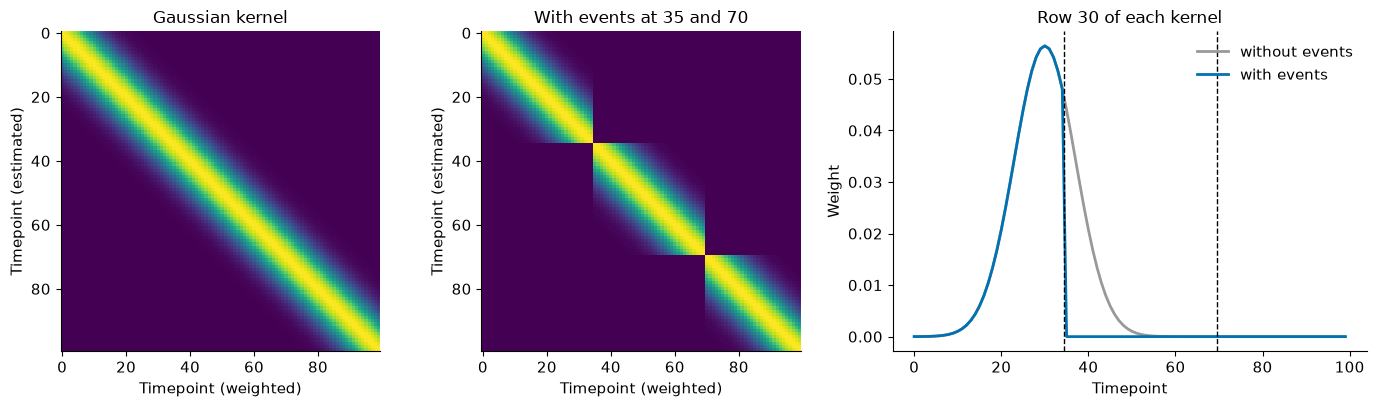

In [3]:
from timecorr.events import mask_kernel

full = tc.gaussian_weights(100, {'var': 50})
bounds = [0, 35, 70]
masked = mask_kernel(full, bounds)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1, 1, 1.4]})
for ax, w, title in zip(axes[:2], (full, masked), ('Gaussian kernel', 'With events at 35 and 70')):
    ax.imshow(w, cmap='viridis')
    ax.set(title=title, xlabel='Timepoint (weighted)', ylabel='Timepoint (estimated)')
axes[2].plot(full[30], color='0.6', lw=2, label='without events')
axes[2].plot(masked[30], lw=2, label='with events')
for b in bounds[1:]:
    axes[2].axvline(b - 0.5, color='k', ls='--', lw=1)
axes[2].set(title='Row 30 of each kernel', xlabel='Timepoint', ylabel='Weight')
axes[2].legend(loc='upper right')
fig.tight_layout()
plt.show()

## 2. Passing boundaries

`events` takes the timepoints at which new events start (0 is implied). The output of each event then equals `timecorr` run on that event alone. `check_boundaries` cleans a boundary set and `block_labels` gives each timepoint's event.

In [4]:
from timecorr.events import block_labels, check_boundaries

rng = np.random.default_rng(0)
data = rng.standard_normal((100, 5))
print('cleaned boundaries:', check_boundaries([70, 35, 35], 100).tolist())
print('event of timepoints 33-37:', block_labels([0, 35, 70], 100)[33:38].tolist())

corrs = tc.timecorr(data, weights_params={'var': 50}, events=[35, 70])
alone = tc.timecorr(data[35:70], weights_function=lambda T, p: full[35:70, 35:70])
print('event 35-69 equals timecorr on its rows alone:', np.allclose(corrs[35:70], alone))

cleaned boundaries: [0, 35, 70]
event of timepoints 33-37: [0, 0, 1, 1, 1]
event 35-69 equals timecorr on its rows alone: True


## 3. Finding events with `tc.segment`

Boundaries often come from a separate description of what happened at each moment, such as features of a stimulus. `tc.segment` fits a hidden Markov model to such a timepoints-by-features array (it needs `hmmlearn`, which it installs on first use). We make a synthetic stimulus whose events last 40 to 120 timepoints, and brain data whose true correlations change at the same boundaries.

In [5]:
T, K, E = 600, 10, 20
iu = np.triu_indices(K, 1)

def make_data(seed):
    rng = np.random.default_rng(seed)
    bounds = [0]
    while bounds[-1] < T:
        bounds.append(bounds[-1] + int(rng.integers(40, 121)))
    bounds = [b for b in bounds if b < T]
    stimulus, brain, truth = np.zeros((T, E)), np.zeros((T, K)), np.zeros((T, len(iu[0])))
    for a, b in zip(bounds, bounds[1:] + [T]):
        stimulus[a:b] = rng.standard_normal(E) + rng.standard_normal((b - a, E))
        A = rng.standard_normal((K, 3))
        C = A @ A.T + np.eye(K)
        C /= np.sqrt(np.outer(np.diag(C), np.diag(C)))
        brain[a:b] = rng.multivariate_normal(np.zeros(K), C, size=b - a)
        truth[a:b] = C[iu]
    wrong = [0] + sorted(rng.choice(np.arange(20, T - 20), len(bounds) - 1, replace=False).tolist())
    return stimulus, brain, truth, np.array(bounds), np.array(wrong)

stimulus, brain, truth, true_bounds, wrong_bounds = make_data(0)
found = tc.segment(stimulus, n=len(true_bounds))
found_auto = tc.segment(stimulus, max_events=15)
print('true boundaries:  ', true_bounds.tolist())
print('segment(n given): ', found.tolist())
print('segment(n=None):  ', found_auto.tolist())

true boundaries:   [0, 108, 199, 280, 341, 405, 448, 494, 535, 589]
segment(n given):  [0, 107, 108, 199, 280, 341, 405, 407, 494, 535]
segment(n=None):   [0, 108, 199, 280, 341, 405, 494, 535]


With `kind='ordered'` (the default) each event happens once, in order; with `n=None` the number of events is chosen from 2 to `max_events`. With `kind='recurring'`, `n` states may come back, and each visit is its own event. Below, a stimulus visits three states in the order A, B, C, A, B, C.

true event starts:  [0, 90, 200, 300, 380, 500]
found:              [0, 90, 200, 300, 380, 500]
state of each event: [2, 1, 0, 2, 1, 0]


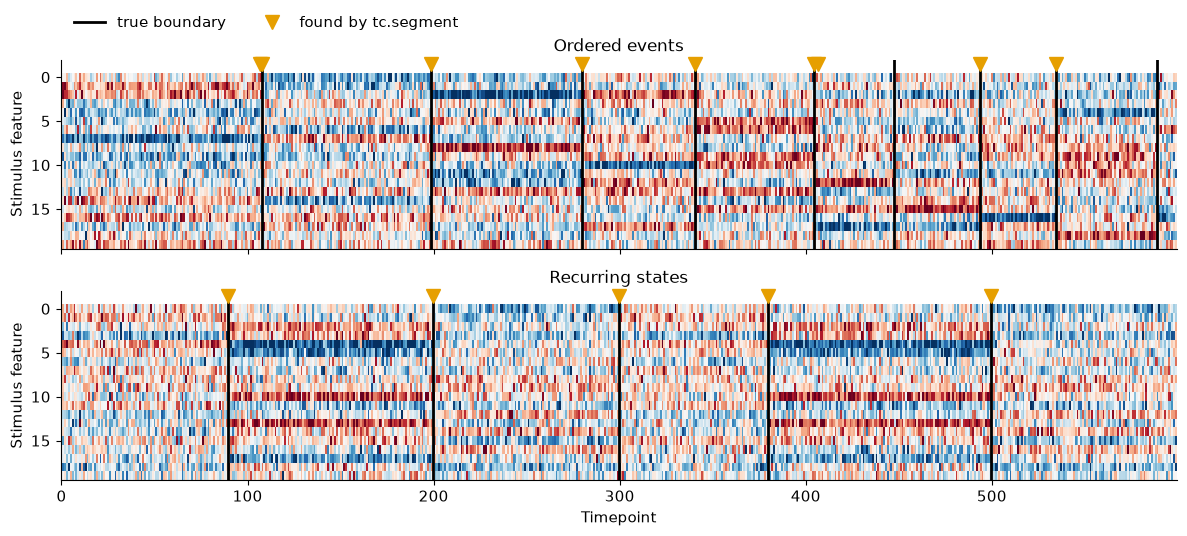

In [6]:
rng = np.random.default_rng(1)
lengths = [90, 110, 100, 80, 120, 100]
states = np.repeat([0, 1, 2, 0, 1, 2], lengths)
recurring = rng.standard_normal((3, E))[states] + rng.standard_normal((T, E))
rec_bounds, rec_states = tc.segment(recurring, n=3, kind='recurring', random_state=0, return_states=True)
print('true event starts: ', np.r_[0, np.cumsum(lengths)[:-1]].tolist())
print('found:             ', rec_bounds.tolist())
print('state of each event:', rec_states[rec_bounds].tolist())

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for ax, emb, true_b, found_b, title in [
        (axes[0], stimulus, true_bounds, found, 'Ordered events'),
        (axes[1], recurring, np.r_[0, np.cumsum(lengths)[:-1]], rec_bounds, 'Recurring states')]:
    ax.imshow(emb.T, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, interpolation='nearest')
    for i, b in enumerate(true_b[1:]):
        ax.axvline(b - 0.5, color='k', lw=2, label='true boundary' if i == 0 else None)
    ax.plot(np.asarray(found_b[1:]) - 0.5, np.full(len(found_b) - 1, -1.5), 'v', color=COLORS[1],
            ms=10, clip_on=False, label='found by tc.segment')
    ax.set(title=title, ylabel='Stimulus feature', ylim=(E - 0.5, -2))
axes[1].set_xlabel('Timepoint')
axes[0].legend(loc='lower left', bbox_to_anchor=(0, 1.08), ncol=2)
fig.tight_layout()
plt.show()

## 4. Do events help?

We estimate the brain correlations with four kernels: no events, the true events, the events found by `tc.segment`, and wrong events (the same number of boundaries at random places, as a control). The score at each timepoint is the correlation between estimated and true correlations. We average it over all timepoints and over those within 10 samples of a true boundary, for 8 datasets.

In [7]:
import warnings

kernel = {'cfun': tc.autofc, 'weights_params': {'var': 100}}

def recovery(brain, truth, events):
    est = np.moveaxis(tc.vec2mat(tc.timecorr(brain, events=events, **kernel)), 2, 0)[:, iu[0], iu[1]]
    e, t = est - est.mean(1, keepdims=True), truth - truth.mean(1, keepdims=True)
    with np.errstate(invalid='ignore', divide='ignore'):  # events of 1-2 timepoints have no estimate
        return (e * t).sum(1) / np.sqrt((e ** 2).sum(1) * (t ** 2).sum(1))

conditions = ['no events', 'true events', 'segmented events', 'wrong events']
scores = {c: [] for c in conditions}
for seed in range(8):
    stim_s, brain_s, truth_s, true_s, wrong_s = make_data(seed)
    near = np.zeros(T, bool)
    for b in true_s[1:]:
        near[max(0, b - 10):b + 10] = True
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        for c, ev in zip(conditions, [None, true_s, tc.segment(stim_s, n=len(true_s)), wrong_s]):
            r = recovery(brain_s, truth_s, ev)
            scores[c].append([np.nanmean(r), np.nanmean(r[near])])
    for message in {str(w.message) for w in caught}:
        print(f'seed {seed}:', message)

print(f'\n{"kernel":18s} {"all timepoints":>16s} {"near a boundary":>16s}  (mean over 8 datasets)')
for c in conditions:
    m = np.mean(scores[c], axis=0)
    print(f'{c:18s} {m[0]:16.3f} {m[1]:16.3f}')

seed 0: 3 of 600 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.
seed 0: 1 of 600 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.
seed 1: 1 of 600 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.
seed 2: 1 of 600 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.


seed 5: 1 of 600 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.
seed 6: 1 of 600 timepoints have fewer than 3 non-zero kernel weights; their correlations are undefined and set to 0.

kernel               all timepoints  near a boundary  (mean over 8 datasets)
no events                     0.883            0.762
true events                   0.912            0.883
segmented events              0.909            0.872
wrong events                  0.869            0.748


Events shorter than 3 timepoints have undefined correlations, which `timecorr` sets to 0 with the warning printed above; the scores leave them out. Near a true boundary, the unrestricted kernel mixes two events; restricting it to the right events avoids that, while wrong events do not.

## 5. Several subjects

`events` may be a list with one entry per subject: `None`, boundaries, or features to segment. `resolve_events` shows how a specification is read, and `distinct_event_sets` groups subjects that share boundaries (they share one kernel).

In [8]:
from timecorr.events import distinct_event_sets, resolve_events

subjects = [rng.standard_normal((T, K)) for _ in range(3)]
spec = [[0, 200, 400], [0, 200, 400], stimulus]
resolved = resolve_events(spec, T, 3)
print('boundaries per subject:', [b.tolist() for b in resolved])
print('subjects grouped by boundaries:', distinct_event_sets(resolved, 3))

per_subject = tc.timecorr(subjects, cfun=tc.autofc, events=spec, weights_params={'var': 100})
print(len(per_subject), 'subjects, each', per_subject[0].shape)

boundaries per subject: [[0, 200, 400], [0, 200, 400], [0, 108, 199, 280, 341, 405, 494, 535]]
subjects grouped by boundaries: [(array([  0, 200, 400]), [0, 1]), (array([  0, 108, 199, 280, 341, 405, 494, 535]), [2])]


3 subjects, each (600, 55)


With `isfc` or `wisfc`, subject `s`'s own events restrict both its data and the other subjects' data it is compared with, so cross-subject correlations assume the subjects' events line up.

## 6. Events by order

In `tc.features`, `events` may be a dict keyed by order (orders not in it are unrestricted). At each order the events restrict both the analysis kernel and the feeding kernel. `resolve_events_by_order` shows the result.

In [9]:
from timecorr.events import resolve_events_by_order

by_order = {1: true_bounds, 2: [0, 300]}
resolved = resolve_events_by_order(by_order, T, 1, 2)
print({k: [b.tolist() for b in v] if v is not None else None for k, v in resolved.items()})

X = tc.features(brain, order=2, cfun=tc.autofc, events=by_order, weights_params={'var': 100})
print('features with events by order:', [x.shape for x in X])

{1: [0, 108, 199, 280, 341, 405, 448, 494, 535, 589], 2: [0, 300]}
features with events by order: [(600, 10), (600, 10), (600, 8)]


The decoders accept `events` too; see the [decoding tutorial](decoding.ipynb).